# Cavity circuit test: Python vs MATLAB

1. Run `cavity_circuit_test.ipynb`.
2. Run all sections of `cavity_circuit_test.mlx`.
3. **Restart Kernel and Run All** here.

This notebook only reads saved outputs. It does not launch MATLAB or recompute either circuit. It checks complex values, dimensions, reference/grid quantities, mode maps, prescribed current, matrices, voltages, powers, and reconstructed fields.

A matching `run_id` is required: rerunning Python invalidates the previous MATLAB result pair. Matching IDs do not protect against manually editing input/result files afterwards.


In [1]:
from pathlib import Path
from datetime import datetime

import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
from IPython.display import Markdown, display

current_directory = Path.cwd().resolve()
project_directory = next(
    path
    for parent in (current_directory, *current_directory.parents)
    for path in (parent, parent / "pyKlyC")
    if (path / "src" / "solver" / "grid.py").exists()
)
test_directory = project_directory / "test" / "5.cavity_circuit_test"

plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.grid": True,
    "axes.axisbelow": "line",
    "grid.color": "gray",
    "grid.linestyle": "--",
    "grid.linewidth": 0.7,
    "grid.alpha": 0.45,
})


In [2]:
python_file = test_directory / "python_results.mat"
matlab_file = test_directory / "matlab_results.mat"
for result_file in (python_file, matlab_file):
    if not result_file.is_file():
        raise FileNotFoundError(f"Missing {result_file}. Run both cavity-circuit tests first.")
    modified = datetime.fromtimestamp(result_file.stat().st_mtime)
    print(f"{result_file.name}: {result_file}")
    print(f"  Last modified (local time): {modified:%Y-%m-%d %H:%M:%S}")

python_results = loadmat(python_file)
matlab_results = loadmat(matlab_file)


python_results.mat: C:\Users\lsito\Desktop\PyKlyC\pyKlyC\test\5.cavity_circuit_test\python_results.mat
  Last modified (local time): 2026-10-16 11:06:24
matlab_results.mat: C:\Users\lsito\Desktop\PyKlyC\pyKlyC\test\5.cavity_circuit_test\matlab_results.mat
  Last modified (local time): 2026-10-16 11:14:07


## 1. Comparison rules

Every exported numeric quantity is checked. Only declared vectors may ignore row/column orientation; matrices keep their dimensions even for a single cavity or harmonic. Complex signs/phases are retained.

Floating-point arrays use `abs(Python - MATLAB) <= atol + rtol*abs(MATLAB)` at **every entry**. Counts, harmonic/type arrays and supplied coupling/phase settings match exactly. Missing, nonfinite, wrongly shaped, or additional untested outputs prevent a pass.

`Ezc` is kV/mm, not V/m. No unit conversion, conjugation, or rescaling is done to make the two results agree.


In [3]:
rtol, atol = 1e-10, 1e-12

# Name: (structure, units). The additional sets below control dtype/exactness.
variables = {
    "Iz0": ("scalar", "A"), "I0": ("scalar", "A"), "U0": ("scalar", "kV"),
    "s": ("scalar", "1"), "vetoc": ("samples", "1"), "vn1": ("samples", "1"),
    "gama": ("scalar", "1"), "w": ("scalar", "rad/s"), "w0": ("cavities", "rad/s"),
    "k0": ("cavities", "1/mm"), "betae": ("scalar", "1/mm"),
    "dz": ("scalar", "mm"), "zi": ("nodes", "mm"), "z": ("nodes", "1"), "dt": ("scalar", "1"),
    "z_mm": ("local_cavities", "mm"), "e_z": ("local_cavities", "mm^(-3/2)"),
    "ez": ("grid_cavities", "mm^(-3/2)"), "C3": ("grid_cavities", "1"),
    "IzDC": ("nodes", "1"), "Iz": ("grid_harmonics", "1"),
    "Pinflag": ("cavities", "1"), "Pin": ("cavities", "W"),
    "Vin": ("cavities", "1"), "flagVnc": ("cavities", "1"),
    "Vnp": ("cavities", "1"), "Vnc": ("cavities", "1"),
    "Mc": ("circuit", "1"), "B": ("unknowns", "1"), "Ibeam": ("cavities", "1"),
    "Vng": ("cavities", "kV"), "Ezc": ("grid_cavities", "kV/mm"),
    "Emz_reconstructed": ("grid_harmonics", "1"), "Ezt": ("grid_snapshots", "kV/mm"),
    "Pport": ("cavities", "W"), "Pwall": ("cavities", "W"), "Pout": ("cavities", "W"),
    "RtoQ_grid": ("cavities", "ohm"),
    "Nt": ("count", "samples"), "Ns": ("count", "harmonics"), "Nc": ("count", "cavities"),
    "N": ("count", "Gaussian intervals"), "theta": ("snapshots", "rad"),
    "drivefactor": ("scalar", "1"), "kai": ("coupling", "1"),
    "gaman": ("cavities", "1"), "Lsb": ("cavities", "rad"),
    "nh": ("cavities", "harmonic"), "type": ("cavities", "classification"),
}
complex_names = {
    "Iz", "Vin", "flagVnc", "Vnp", "Vnc", "Mc", "B", "Ibeam", "Vng",
    "Ezc", "Emz_reconstructed", "kai", "gaman",
}
exact_names = {"Nt", "Ns", "Nc", "N", "Pinflag", "nh", "type", "kai", "gaman", "Lsb", "theta"}
matrix_structures = {"local_cavities", "grid_cavities", "grid_harmonics", "grid_snapshots", "circuit", "coupling"}
text_names = {"case_name", "beam_transport", "cavityname", "run_id"}

def get_count(results, name):
    values = results.get(name, np.array([]))
    if values.shape != (1, 1) or values.dtype.kind not in "iuf":
        return 0
    value = values.item()
    return int(value) if np.isfinite(value) and value >= 1 and value == np.floor(value) else 0

def expected_shape(results, structure):
    nodes = results.get("zi", np.array([])).size
    snapshots = results.get("theta", np.array([])).size
    Nc, Ns = get_count(results, "Nc"), get_count(results, "Ns")
    shapes = {
        "local_cavities": (get_count(results, "N") + 1, Nc),
        "grid_cavities": (nodes, Nc), "grid_harmonics": (nodes, Ns),
        "grid_snapshots": (nodes, snapshots), "circuit": (2*Nc, 2*Nc),
        "coupling": (Nc, Nc),
        "samples": (get_count(results, "Nt"),), "cavities": (Nc,),
        "nodes": (nodes,), "unknowns": (2*Nc,), "snapshots": (snapshots,),
        "scalar": (1,), "count": (1,),
    }
    return shapes[structure]


In [4]:
text_matches = True
for name in sorted(text_names):
    values = []
    for results in (python_results, matlab_results):
        value = results.get(name, np.array([]))
        values.append(value.item() if value.size == 1 and value.dtype.kind in "US" else "")
    matched = bool(values[0]) and values[0] == values[1]
    text_matches = text_matches and matched
    print(f"{name}: Python={values[0]!r}; MATLAB={values[1]!r}; match={matched}")

comparison = []
pairs = {}
for name, (structure, units) in variables.items():
    python_values = python_results.get(name)
    matlab_values = matlab_results.get(name)
    row = {
        "name": name, "units": units,
        "python_shape": None if python_values is None else python_values.shape,
        "matlab_shape": None if matlab_values is None else matlab_values.shape,
        "max_absolute": None, "max_relative": None,
        "status": "NOT TESTED", "note": "",
    }
    comparison.append(row)
    if python_values is None or matlab_values is None:
        row["note"] = "Missing variable."
        continue
    allowed_types = "iufc" if name in complex_names else "iuf"
    if any(values.dtype.kind not in allowed_types for values in (python_values, matlab_values)):
        row["note"] = "Unexpected data type."
        continue

    shape_ok = True
    for values, results in ((python_values, python_results), (matlab_values, matlab_results)):
        shape = expected_shape(results, structure)
        shape_ok = shape_ok and all(dimension >= 1 for dimension in shape)
        if structure in matrix_structures:
            shape_ok = shape_ok and values.shape == shape
        else:
            shape_ok = shape_ok and values.ndim == 2 and 1 in values.shape and values.size == shape[0]
    if not shape_ok:
        row["note"] = f"Unexpected {structure} dimensions."
        continue

    dtype = complex if name in complex_names else float
    python_values, matlab_values = python_values.astype(dtype), matlab_values.astype(dtype)
    if structure not in matrix_structures:
        python_values, matlab_values = python_values.reshape(-1), matlab_values.reshape(-1)
    if python_values.shape != matlab_values.shape:
        row["note"] = "Different dimensions."
        continue
    if not (np.all(np.isfinite(python_values)) and np.all(np.isfinite(matlab_values))):
        row["note"] = "NaN or infinity found."
        continue
    if structure == "count" and (not get_count(python_results, name) or not get_count(matlab_results, name)):
        row["note"] = "Counts must be positive integers."
        continue

    pairs[name] = (python_values, matlab_values)
    error = np.abs(python_values - matlab_values)
    row["max_absolute"] = np.max(error)
    nonzero = matlab_values != 0
    if np.any(nonzero):
        row["max_relative"] = np.max(error[nonzero] / np.abs(matlab_values[nonzero]))
    if name in exact_names:
        passed = np.array_equal(python_values, matlab_values)
        row["note"] = "Exact values"
    else:
        passed = np.all(error <= atol + rtol * np.abs(matlab_values))
        row["note"] = "Absolute + relative tolerance"
    row["status"] = "PASS" if passed else "FAIL"

exported_names = {
    name for results in (python_results, matlab_results) for name in results if not name.startswith("__")
}
extra_names = sorted(exported_names - variables.keys() - text_names)
all_passed = text_matches and all(row["status"] == "PASS" for row in comparison) and not extra_names


beam_transport: Python='constant_speed'; MATLAB='constant_speed'; match=True
case_name: Python='bunched'; MATLAB='bunched'; match=True
cavityname: Python='guide_cavity_1 guide_cavity_2 guide_cavity_3 guide_cavity_4 guide_cavity_5'; MATLAB='guide_cavity_1 guide_cavity_2 guide_cavity_3 guide_cavity_4 guide_cavity_5'; match=True
run_id: Python='4e1176ffe19f4abea12465107113fa7c'; MATLAB='4e1176ffe19f4abea12465107113fa7c'; match=True


## 2. Numerical summary

Absolute errors use the listed units. Relative errors near a zero beam harmonic can be large even when absolute errors are at roundoff; the pass rule includes both tolerances. No entries are excluded from the comparison.


In [5]:
def format_error(value):
    return "-" if value is None else f"{value:.3e}"

table = [
    "| Variable | Units | Python shape | MATLAB shape | Max absolute error | Max relative error | Result | Rule / issue |",
    "|---|---|---|---|---|---|---|---|",
]
for row in comparison:
    table.append(
        f"| {row['name']} | {row['units']} | {row['python_shape']} | {row['matlab_shape']} "
        f"| {format_error(row['max_absolute'])} | {format_error(row['max_relative'])} "
        f"| {row['status']} | {row['note']} |"
    )
display(Markdown("\n".join(table)))
print("Case, transport, cavity order and run ID match:", text_matches)
if extra_names:
    print("NOT TESTED: unexpected exported variables:", ", ".join(extra_names))
passed_count = sum(row["status"] == "PASS" for row in comparison)
print(f"Tolerance: rtol={rtol:g}, atol={atol:g}")
print(f"{passed_count}/{len(variables)} numerical outputs/metadata passed.")
print("Overall: PASS" if all_passed else "Overall: NOT PASSED — inspect the table above.")


| Variable | Units | Python shape | MATLAB shape | Max absolute error | Max relative error | Result | Rule / issue |
|---|---|---|---|---|---|---|---|
| Iz0 | A | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| I0 | A | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| U0 | kV | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| s | 1 | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| vetoc | 1 | (1, 256) | (1, 256) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| vn1 | 1 | (1, 256) | (1, 256) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| gama | 1 | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| w | rad/s | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| w0 | rad/s | (1, 5) | (1, 5) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| k0 | 1/mm | (1, 5) | (1, 5) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| betae | 1/mm | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| dz | mm | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| zi | mm | (1, 3806) | (3806, 1) | 4.547e-13 | 2.334e-16 | PASS | Absolute + relative tolerance |
| z | 1 | (1, 3806) | (3806, 1) | 1.421e-14 | 2.343e-16 | PASS | Absolute + relative tolerance |
| dt | 1 | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| z_mm | mm | (201, 5) | (201, 5) | 2.842e-14 | 2.419e-14 | PASS | Absolute + relative tolerance |
| e_z | mm^(-3/2) | (201, 5) | (201, 5) | 2.168e-18 | 7.039e-15 | PASS | Absolute + relative tolerance |
| ez | mm^(-3/2) | (3806, 5) | (3806, 5) | 9.714e-17 | 2.100e-13 | PASS | Absolute + relative tolerance |
| C3 | 1 | (3806, 5) | (3806, 5) | 7.095e-16 | 2.101e-13 | PASS | Absolute + relative tolerance |
| IzDC | 1 | (1, 3806) | (3806, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| Iz | 1 | (3806, 8) | (3806, 8) | 2.631e-14 | 1.704e-13 | PASS | Absolute + relative tolerance |
| Pinflag | 1 | (1, 5) | (1, 5) | 0.000e+00 | 0.000e+00 | PASS | Exact values |
| Pin | W | (1, 5) | (1, 5) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| Vin | 1 | (1, 5) | (1, 5) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| flagVnc | 1 | (1, 5) | (1, 5) | 0.000e+00 | - | PASS | Absolute + relative tolerance |
| Vnp | 1 | (1, 5) | (1, 5) | 1.241e-16 | 2.813e-16 | PASS | Absolute + relative tolerance |
| Vnc | 1 | (1, 5) | (1, 5) | 2.665e-15 | 4.590e-16 | PASS | Absolute + relative tolerance |
| Mc | 1 | (10, 10) | (10, 10) | 6.939e-18 | 1.268e-16 | PASS | Absolute + relative tolerance |
| B | 1 | (1, 10) | (10, 1) | 1.251e-17 | 4.534e-16 | PASS | Absolute + relative tolerance |
| Ibeam | 1 | (1, 5) | (1, 5) | 1.251e-17 | 4.534e-16 | PASS | Absolute + relative tolerance |
| Vng | kV | (1, 5) | (1, 5) | 4.687e-13 | 7.984e-16 | PASS | Absolute + relative tolerance |
| Ezc | kV/mm | (3806, 5) | (3806, 5) | 1.623e-13 | 2.097e-13 | PASS | Absolute + relative tolerance |
| Emz_reconstructed | 1 | (3806, 8) | (3806, 8) | 2.895e-14 | 2.096e-13 | PASS | Absolute + relative tolerance |
| Ezt | kV/mm | (3806, 4) | (3806, 4) | 1.443e-13 | 2.099e-13 | PASS | Absolute + relative tolerance |
| Pport | W | (1, 5) | (1, 5) | 3.725e-09 | 7.118e-16 | PASS | Absolute + relative tolerance |
| Pwall | W | (1, 5) | (1, 5) | 1.746e-10 | 1.028e-15 | PASS | Absolute + relative tolerance |
| Pout | W | (1, 5) | (1, 5) | 1.863e-09 | 7.118e-16 | PASS | Absolute + relative tolerance |
| RtoQ_grid | ohm | (1, 5) | (1, 5) | 1.421e-13 | 1.035e-15 | PASS | Absolute + relative tolerance |
| Nt | samples | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Exact values |
| Ns | harmonics | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Exact values |
| Nc | cavities | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Exact values |
| N | Gaussian intervals | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Exact values |
| theta | rad | (1, 4) | (1, 4) | 0.000e+00 | 0.000e+00 | PASS | Exact values |
| drivefactor | 1 | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| kai | 1 | (5, 5) | (5, 5) | 0.000e+00 | - | PASS | Exact values |
| gaman | 1 | (1, 5) | (1, 5) | 0.000e+00 | - | PASS | Exact values |
| Lsb | rad | (1, 5) | (1, 5) | 0.000e+00 | 0.000e+00 | PASS | Exact values |
| nh | harmonic | (1, 5) | (1, 5) | 0.000e+00 | 0.000e+00 | PASS | Exact values |
| type | classification | (1, 5) | (1, 5) | 0.000e+00 | 0.000e+00 | PASS | Exact values |

Case, transport, cavity order and run ID match: True
Tolerance: rtol=1e-10, atol=1e-12
49/49 numerical outputs/metadata passed.
Overall: PASS


## 3. Complex circuit and gap voltages

The top row overlays real and imaginary parts. The bottom row is Python minus MATLAB. The comparison above also checks every matrix element and source coefficient.


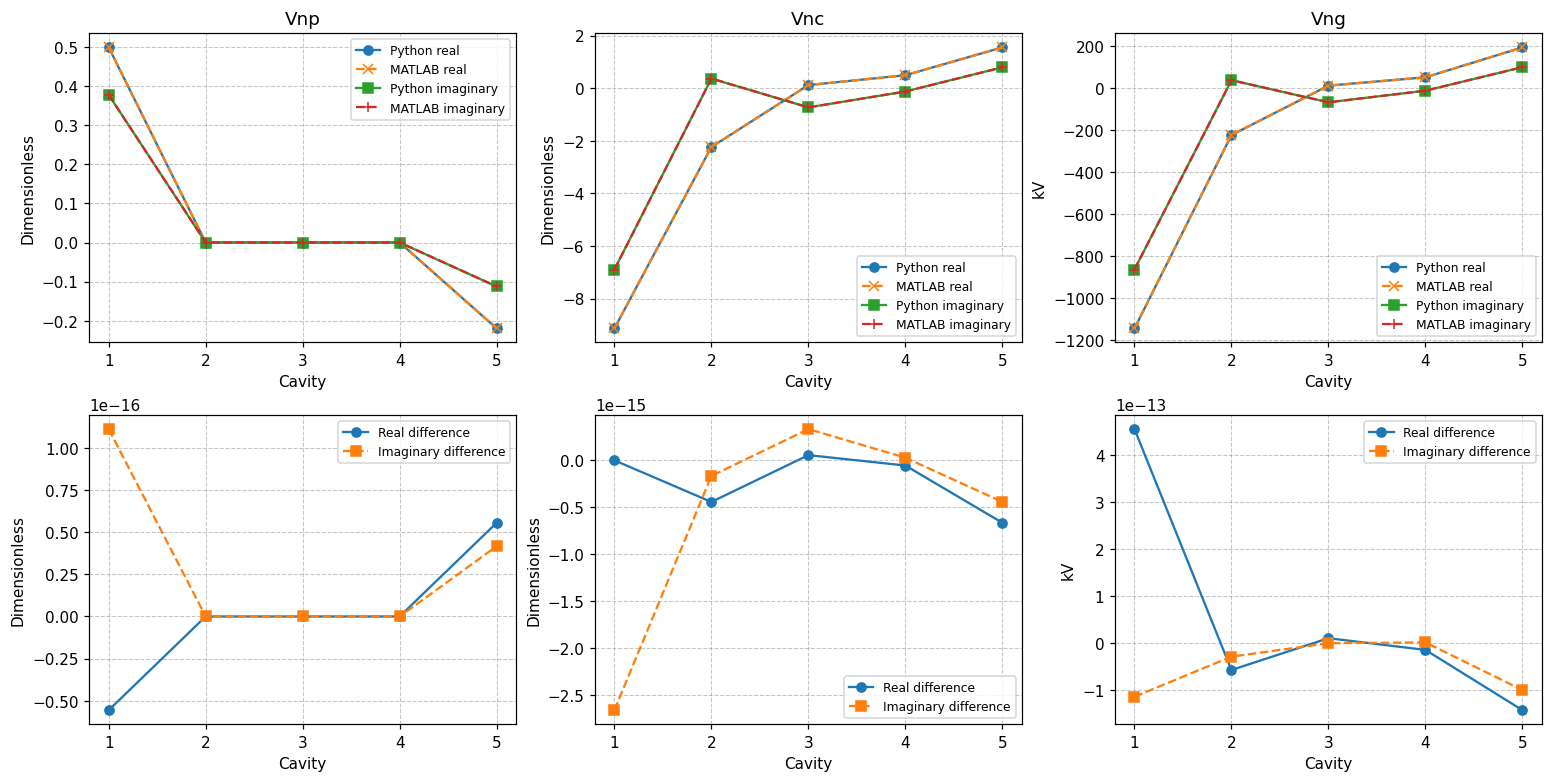

In [6]:
if all(name in pairs for name in ("Nc", "Vnp", "Vnc", "Vng")):
    indices = np.arange(1, len(pairs["Vnc"][0]) + 1)
    fig, axes = plt.subplots(2, 3, figsize=(14, 7), layout="constrained")
    for column, name in enumerate(("Vnp", "Vnc", "Vng")):
        py, ma = pairs[name]
        axes[0, column].plot(indices, py.real, "o-", label="Python real")
        axes[0, column].plot(indices, ma.real, "x--", label="MATLAB real")
        axes[0, column].plot(indices, py.imag, "s-", label="Python imaginary")
        axes[0, column].plot(indices, ma.imag, "+--", label="MATLAB imaginary")
        axes[0, column].set_title(name)
        difference = py-ma
        axes[1, column].plot(indices, difference.real, "o-", label="Real difference")
        axes[1, column].plot(indices, difference.imag, "s--", label="Imaginary difference")
        axes[1, column].ticklabel_format(axis="y", style="sci", scilimits=(0,0), useOffset=False)
        for ax in axes[:, column]:
            ax.set(xlabel="Cavity", xticks=indices, ylabel="kV" if name == "Vng" else "Dimensionless")
            ax.legend(fontsize=8)
    plt.show()


## 4. Reconstructed fields: overlays and differences

Every cavity column is compared as a complex field, without flattening or taking magnitudes first. The harmonic-grouped field and instantaneous snapshots are also checked in the main table.


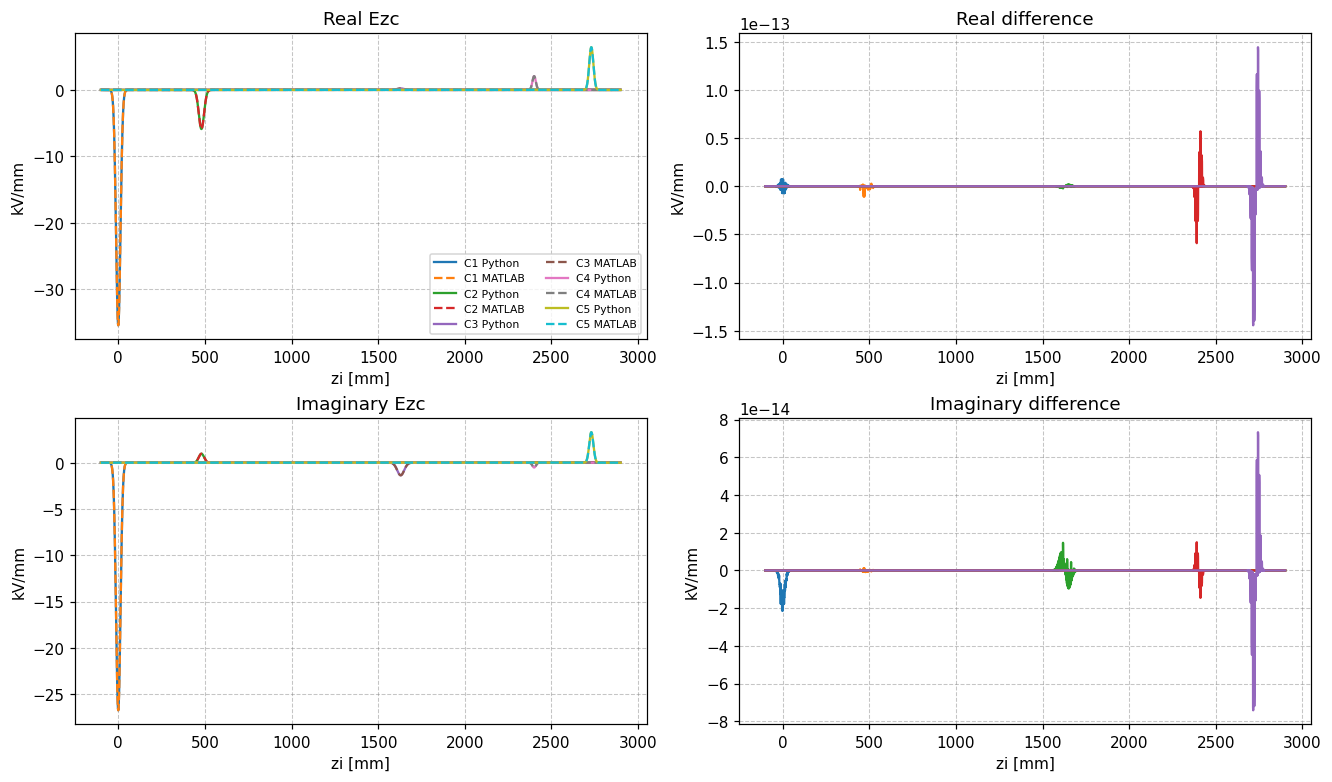

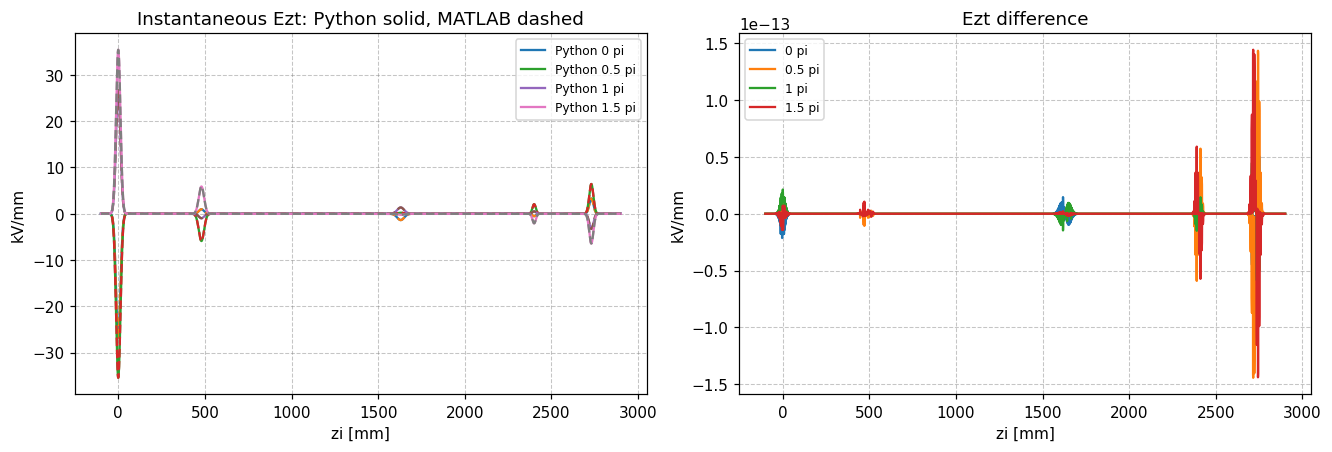

In [7]:
if all(name in pairs for name in ("zi", "Ezc", "Ezt", "theta")):
    zi = pairs["zi"][0]
    py, ma = pairs["Ezc"]
    fig, axes = plt.subplots(2, 2, figsize=(12, 7), layout="constrained")
    for k in range(py.shape[1]):
        axes[0, 0].plot(zi, py[:, k].real, label=f"C{k+1} Python")
        axes[0, 0].plot(zi, ma[:, k].real, "--", label=f"C{k+1} MATLAB")
        axes[1, 0].plot(zi, py[:, k].imag)
        axes[1, 0].plot(zi, ma[:, k].imag, "--")
        axes[0, 1].plot(zi, (py[:, k]-ma[:, k]).real)
        axes[1, 1].plot(zi, (py[:, k]-ma[:, k]).imag)
    axes[0, 0].set_title("Real Ezc")
    axes[1, 0].set_title("Imaginary Ezc")
    axes[0, 1].set_title("Real difference")
    axes[1, 1].set_title("Imaginary difference")
    axes[0, 0].legend(ncol=2, fontsize=7)
    for ax in axes.flat:
        ax.set(xlabel="zi [mm]", ylabel="kV/mm")
    plt.show()

    fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
    py, ma = pairs["Ezt"]
    for j, phase in enumerate(pairs["theta"][0]):
        axes[0].plot(zi, py[:, j], label=f"Python {phase/np.pi:g} pi")
        axes[0].plot(zi, ma[:, j], "--")
        axes[1].plot(zi, py[:, j]-ma[:, j], label=f"{phase/np.pi:g} pi")
    axes[0].set_title("Instantaneous Ezt: Python solid, MATLAB dashed")
    axes[1].set_title("Ezt difference")
    for ax in axes:
        ax.set(xlabel="zi [mm]", ylabel="kV/mm")
        ax.legend(fontsize=8)
    plt.show()


## 5. Matrix and excitation errors


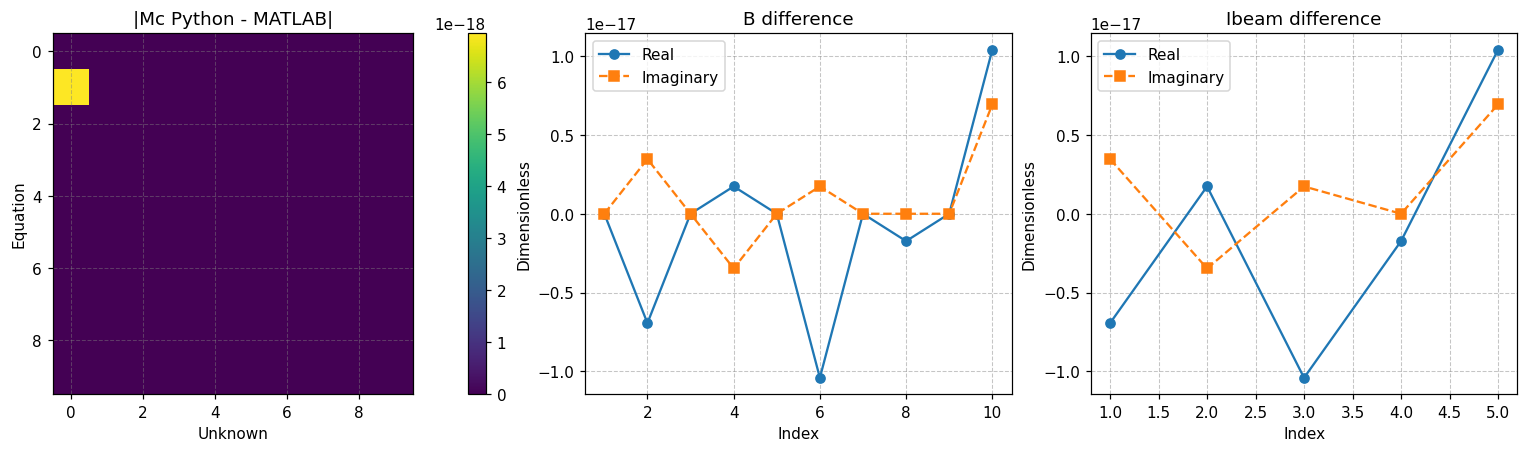

In [8]:
if all(name in pairs for name in ("Mc", "B", "Ibeam")):
    fig, axes = plt.subplots(1, 3, figsize=(14, 4), layout="constrained")
    error = np.abs(pairs["Mc"][0]-pairs["Mc"][1])
    im = axes[0].imshow(error, aspect="equal")
    fig.colorbar(im, ax=axes[0])
    axes[0].set(title="|Mc Python - MATLAB|", xlabel="Unknown", ylabel="Equation")
    for ax, name in zip(axes[1:], ("B", "Ibeam")):
        difference = pairs[name][0]-pairs[name][1]
        ax.plot(np.arange(1, len(difference)+1), difference.real, "o-", label="Real")
        ax.plot(np.arange(1, len(difference)+1), difference.imag, "s--", label="Imaginary")
        ax.set(title=f"{name} difference", xlabel="Index", ylabel="Dimensionless")
        ax.legend()
    plt.show()


## 6. Final result

A pass demonstrates agreement for this **single fixed-frequency circuit problem and documented field reconstruction**. It does not demonstrate a working `Emz` update in the original solver, electron tracking, self-consistent beam loading, nonlinear convergence, or physical validation of a coupled geometry.


In [9]:
assert all_passed, "Cavity-circuit comparison did not pass. Review the numerical summary."
print(f"PASS: all {len(variables)} numerical outputs/settings and all four text identifiers agree.")


PASS: all 49 numerical outputs/settings and all four text identifiers agree.
